# Glasauer & Shi (2022): two-state model versus 3SKF

This notebook asks one narrow question: **if both models are fitted to the randomized condition, can they predict
the change produced solely by putting the same durations into random-walk order?**

The comparison follows the paper's evidence order:

1. central tendency (CT);
2. lag-1 serial dependence (SD);
3. the randomized-condition partial-correlation check;
4. duration-resolved data–model correspondence and $R^2$;
5. only then, the 3SKF v3 model space adapted to this design: which parameters change between the two sequence
   types.

Static and simple-iterative models are not included. There is no invented PPC pass/fail rule. Model curves are
deterministic trial-wise predictions, and every error bar is **SEM across participants**, as in the original paper.
The 3SKF model is **3SKF v3**: the memory filter has no persistence, and a share $\phi$ of the previous fast deviation
is borrowed only at the readout. The comparison uses the corrected response-bias level **B2**.

In [1]:
import os
import sys

os.environ.update(GKF_SCALE="lin", GKF_CORE="reduced", GKF_BOUNDS="v3", GKF_INIT="gs", GKF_NOISELESS="1",
                  GKF_QDIAG="1", GKF_READOUT="1")
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sdu.model import engine as G
from sdu.reports import plots as P
from sdu.reports import glasauer_shi as R

assert G.READOUT
P.use_style()
pd.set_option("display.precision", 3)
pd.set_option("display.float_format", lambda value: f"{value:.4f}")
D = R.Data()
print(f"{len(D.participants)} participants; 400 trials per condition before invalid responses are masked")

14 participants; 400 trials per condition before invalid responses are masked


## 1. Models and the paper-aligned test

Glasauer and Shi encode duration as $z_i=\log(1+d_i/d_0)$, with $d_0=.1$ s. Their two-state transition and
measurement equations are

$$
\mathbf F=\begin{pmatrix}0&1\\0&1\end{pmatrix},\qquad
\mathbf Q=\begin{pmatrix}v&0\\0&q\end{pmatrix},\qquad
\mathbf H=(1,0),
$$

and the supplied reference code decodes the estimate as

$$\hat d_i=d_0\left[\exp(\hat x_i+\Delta x)-1\right].$$

Its three fitted quantities are $v/r$, $q/r$, and $\Delta x$. We fit them by trial-wise least squares, separately
for each participant, from the randomized condition only.

The 3SKF model is **3SKF C3-S0-B2**, the model selected for our Experiment 1, applied unchanged. These labels are
used in every figure and table below.

**What C3, S0 and B2 mean here.** This design has no coherence manipulation; every trial has the same $c$:

* **C3** lets only the bias-state noise $q_3$ depend on coherence, and with a constant $c$ that ratio multiplies by 1;
* **S0** has no switch operation, and there are no switches here anyway;
* **B2** adds a slowly drifting response bias $b_i=\lambda b_{i-1}+\eta_i$ to the report, $y_i=\hat u_i+b_i+e_i$; the
  observer never sees it, and it only makes consecutive reports drift together;
* of $\phi^L$ and $\phi^H$, only one is ever used.

On these data C3-S0-B2 is therefore exactly 3SKF v3 with the corrected response-bias state B2 and a single readout
persistence $\phi$. Every other C and S level of the v3 space reduces to the same model, so C and S are not tested
here. The comparison model, **3SKF B0 (no bias state)**, removes the bias state.

### The 3SKF v3 model space (all dimensions)

Every model is one level of each of three dimensions. Each coherence modulation is fitted as a Low/High ratio in
$[0.1,10]$: $q_j^{\text{eff}}(\text{Low})/q_j^{\text{eff}}(\text{High})=\exp(0.4\,\alpha_{q_j})$ and $r_{\text{low}}/1$.

#### C: which noise depends on coherence (15 levels, as in the 135-model space)

| C | $q_1$ fast state ($\alpha_{q_1}$) | $q_2$ slow state ($\alpha_{q_2}$) | $q_3$ bias state ($\alpha_{q_3}$) | $R$ measurement ($r_{\text{low}}$) | extra parameters | contains | with B0 |
|---|:-:|:-:|:-:|:-:|:-:|---|:-:|
| C1 | ✓ | | | | 1 | — | yes |
| C2 | | ✓ | | | 1 | — | yes |
| C3 | | | ✓ | | 1 | — | no |
| C4 | | | | ✓ | 1 | — | yes |
| C5 | ✓ | | | ✓ | 2 | C1, C4 | yes |
| C6 | | ✓ | | ✓ | 2 | C2, C4 | yes |
| C7 | | | ✓ | ✓ | 2 | C3, C4 | no |
| C8 | ✓ | ✓ | | | 2 | C1, C2 | yes |
| C9 | ✓ | | ✓ | | 2 | C1, C3 | no |
| C10 | | ✓ | ✓ | | 2 | C2, C3 | no |
| C11 | ✓ | ✓ | | ✓ | 3 | C1, C2, C4, C5, C6, C8 | yes |
| C12 | ✓ | | ✓ | ✓ | 3 | C1, C3, C4, C5, C7, C9 | no |
| C13 | | ✓ | ✓ | ✓ | 3 | C2, C3, C4, C6, C7, C10 | no |
| C14 | ✓ | ✓ | ✓ | | 3 | C1, C2, C3, C8, C9, C10 | no |
| C15 | ✓ | ✓ | ✓ | ✓ | 4 | all | no |

"Contains" means the level reduces to the smaller one when the extra modulations are 0 ($r_{\text{low}}=1$). A C level
with $q_3$ is not combined with B0, because without a bias state $q_3$ does nothing.

#### S: what happens on a coherence switch, $\mathrm{coh}_i\neq\mathrm{coh}_{i-1}$ (4 levels)

On repeat trials every S level equals S0. S0–S2 are the 135-model switch mechanisms, with $\gamma$ and $\kappa$ as
there; S3 is new.

| S | name | on a switch trial | extra parameters |
|---|---|---|:-:|
| S0 | no switch effect | nothing | 0 |
| S1 | state reset | before the prediction, $\hat m\leftarrow(1-\gamma)\,\hat m+\gamma\,\mu_0$; $\hat x$ is unchanged at that moment | $\gamma$ |
| S2 | gain reduction | $\mathbf K\leftarrow(1-\kappa)\,\mathbf K$, and $\mathbf P$ is updated with the reduced gain | $\kappa$ |
| S3 **(v3)** | readout reset | $\phi_i=0$: the previous fast deviation is not borrowed | 0 |

#### B: the bias state (3 levels)

The 135-model labels are given for comparison. 135 B1 (decoupled: the bias is tracked but has no effect) is
equivalent to having no bias state, B0 here.

| B | 135 label | where the bias acts | equations | extra parameters |
|---|---|---|---|:-:|
| B0 | B1 (decoupled) | none | response $\hat u_i+d_0^{\text{eff}}$ | 0 |
| B1 | B2 (prediction) | in the observer's prediction | $F_{1,3}=1$: $\hat x_i^-=\hat m_{i-1}+\hat b_{i-1}$; the observer updates $\hat b$ from the measurement | $\lambda,\ q_3$ |
| B2 | B3 (response), corrected | in the response, latent | $F_{1,3}=0$; response $\hat u_i+b_i+d_0^{\text{eff}}$ with $b_i=\lambda b_{i-1}+\eta_i$, $\eta_i\sim\mathcal N(0,q_3^{\text{eff}})$; the observer never sees $b_i$ | $\lambda,\ q_3$ |

#### Parameters shared by every model

| parameter | meaning |
|---|---|
| $q_1,\ q_2$ | process noise of the fast and slow states |
| $\phi^L,\ \phi^H$ **(v3)** | share of the previous fast deviation borrowed at the readout, current Low / High, in $[0,1]$ |
| $d_0,\ \alpha_{d_0}$ | response offset and its coherence modulation, $d_0^{\text{eff}}=d_0+\alpha_{d_0}(1-\mathrm{coh})$ |
| $\sigma_e$ | response noise |

The number of parameters $k$ is 7 shared, plus 1–4 (C), plus 1 (S1, S2), plus 2 (B1, B2). It runs from 8 (e.g.
C1-S0-B0) to 14 (C15-S1-B2). Model count: 15 C × 4 S × 3 B = 180, minus the 8 C levels with $q_3$ × 4 S under B0, gives
148.

**On these data.** Without coherence variation, every C level and every S level reduces to the same model. Only B
(B0, B1, B2) and the single $\phi$ remain.

In the notation of the 135-model appendix:
* the state is $\mathbf s_i=[\hat x_i,\hat m_i,\hat b_i]^\top$, with $\mathbf Q=\operatorname{diag}(q_1,q_2,q_3)$;
* the measurement is $z_i=s_i$, the presented duration, with $\mathbf H=[1,0,0]$.

Under B2, $F_{1,3}=0$, so the filter is the 135-model filter without a bias coupling. The readout (v3) borrows a share
$\phi$ of the previous fast deviation $\hat f_{i-1}=\hat x_{i-1}-\hat m_{i-1}$, and B2 adds the latent response bias
$b_i$:

$$
\mathbf F=\begin{bmatrix}0&1&0\\0&1&0\\0&0&\lambda\end{bmatrix},\qquad
\hat u_i=\hat x_i+\big(1-K_i^{(x)}\big)\,\phi\,\hat f_{i-1},\qquad
y_i=\hat u_i+b_i+d_0+\varepsilon_i,\qquad b_i=\lambda b_{i-1}+\eta_i .
$$

$\phi=0$ is the nested model without persistence.

For both models, the fitted randomized parameters are frozen before the random-walk stimulus sequence is supplied.
The random-walk responses therefore never enter the primary model fits.

In [2]:
participant_statistics = R.participant_statistics(D)

## 2. CT and SD

CT is $1-$ the slope of reproduction on current duration. SD is the slope of current reproduction error on the
previous duration. These are the paper's simple-regression definitions. In the randomized condition, the paper
additionally checks $r(e_i,s_{i-1}\mid s_i)$ and the reverse partial correlation. In the random-walk condition,
$s_i$ and $s_{i-1}$ are intentionally highly autocorrelated; the paper does not estimate controlled CT/SD there.
Instead, it asks whether parameters fitted to randomized trials predict the random-walk CT/SD pattern. Lag 2 is
reported later as a supplementary check.

The figure below is the analogue of the paper's condition summary: participant means $\pm$ participant-level SEM.
It is not a posterior-predictive interval.

CT             SD       
                                     mean    sem    mean    sem
condition   model                                              
random walk 3SKF C3-S0-B2          0.0910 0.0270 -0.0840 0.0270
            Glasauer–Shi two-state 0.0140 0.0380 -0.0060 0.0380
            data                   0.0960 0.0370 -0.0860 0.0370
randomized  3SKF C3-S0-B2          0.4520 0.0460  0.1110 0.0140
            Glasauer–Shi two-state 0.4390 0.0480  0.0950 0.0180
            data                   0.4550 0.0460  0.1090 0.0150

,mean,std,t(13),p
measure,,,,
"partial r(error, previous | current)",0.1966,0.0703,10.4558,<.0001
"partial r(error, current | previous)",-0.6025,0.1559,-14.4599,<.0001


,mean,min,max
condition,,,
random walk,0.9920,0.9850,0.9940
randomized,0.0180,-0.0910,0.0470


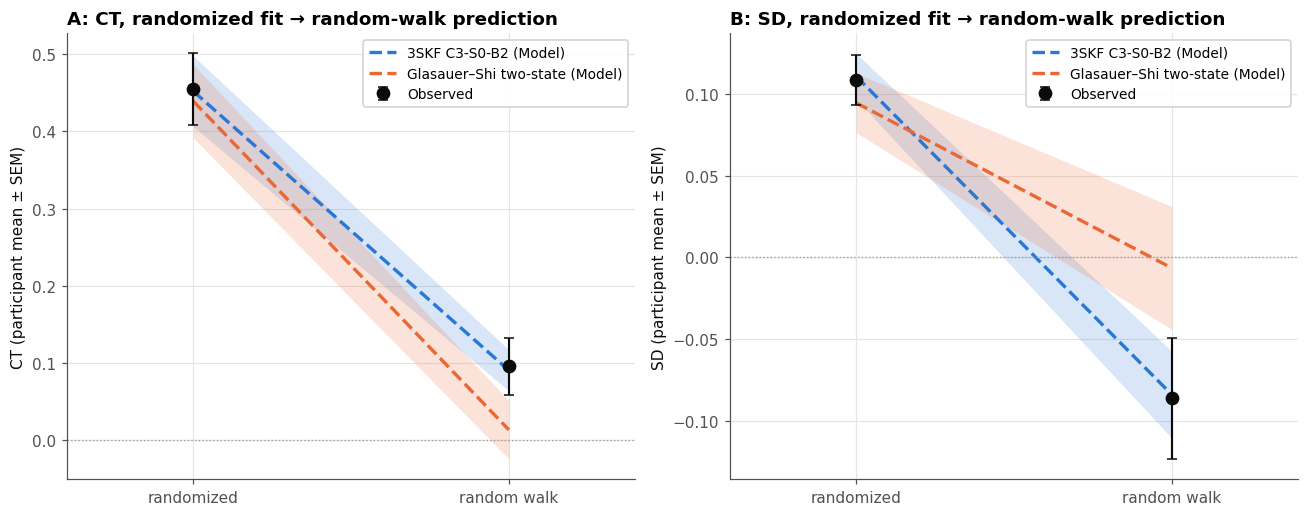

model − data  SEM of difference   t(13)      p
model                  measure                                                
Glasauer–Shi two-state CT            -0.0820             0.0480 -1.7230 0.1090
                       SD             0.0800             0.0480  1.6570 0.1220
3SKF C3-S0-B2          CT            -0.0050             0.0420 -0.1230 0.9040
                       SD             0.0020             0.0420  0.0540 0.9580

,randomized,random walk,t(13),p,randomized > random walk
measure,,,,,
CT,0.4549,0.0958,7.2913,0.0000,14/14
SD,0.1087,-0.0863,5.1563,0.0002,13/14


In [3]:
display(R.ct_sd_summary(participant_statistics))
display(R.partial_correlations(participant_statistics))
display(R.predictor_correlation(participant_statistics))
R.plot_ct_sd(participant_statistics)
plt.show()
display(R.random_walk_prediction_tests(participant_statistics))
display(R.condition_tests(participant_statistics))

**Reading.**

* <span style="color:#b71c1c">**The sequence type changes CT and SD strongly.** CT falls from .455 (randomized) to
  .096 (random walk), $t(13)=7.29$, $p<.001$, in 14 of 14 participants. SD changes sign, from .109 to $-.086$,
  $t(13)=5.16$, $p<.001$, in 13 of 14 participants.</span>
* In random walk, the current and previous durations correlate at .99, so these simple-regression slopes mainly
  reflect the stimulus order. The paper's point is that the change follows from the order alone, with the observer's
  parameters unchanged.
* <span style="color:#b71c1c">With every randomized-fitted parameter frozen, **3SKF C3-S0-B2 predicts the random-walk
  CT and SD** (.091 and $-.084$ against .096 and $-.086$, paired $p=.90$ and $.96$). The two-state model does not
  (.014 and $-.006$).</span>

## 3. Duration-resolved correspondence

For every participant, error is averaged within the paper's 0.1-s duration bins. Those participant curves are then
averaged; the bars and ribbons are SEM across participants at each bin. There are no simulated cohorts and no
quantile bands.

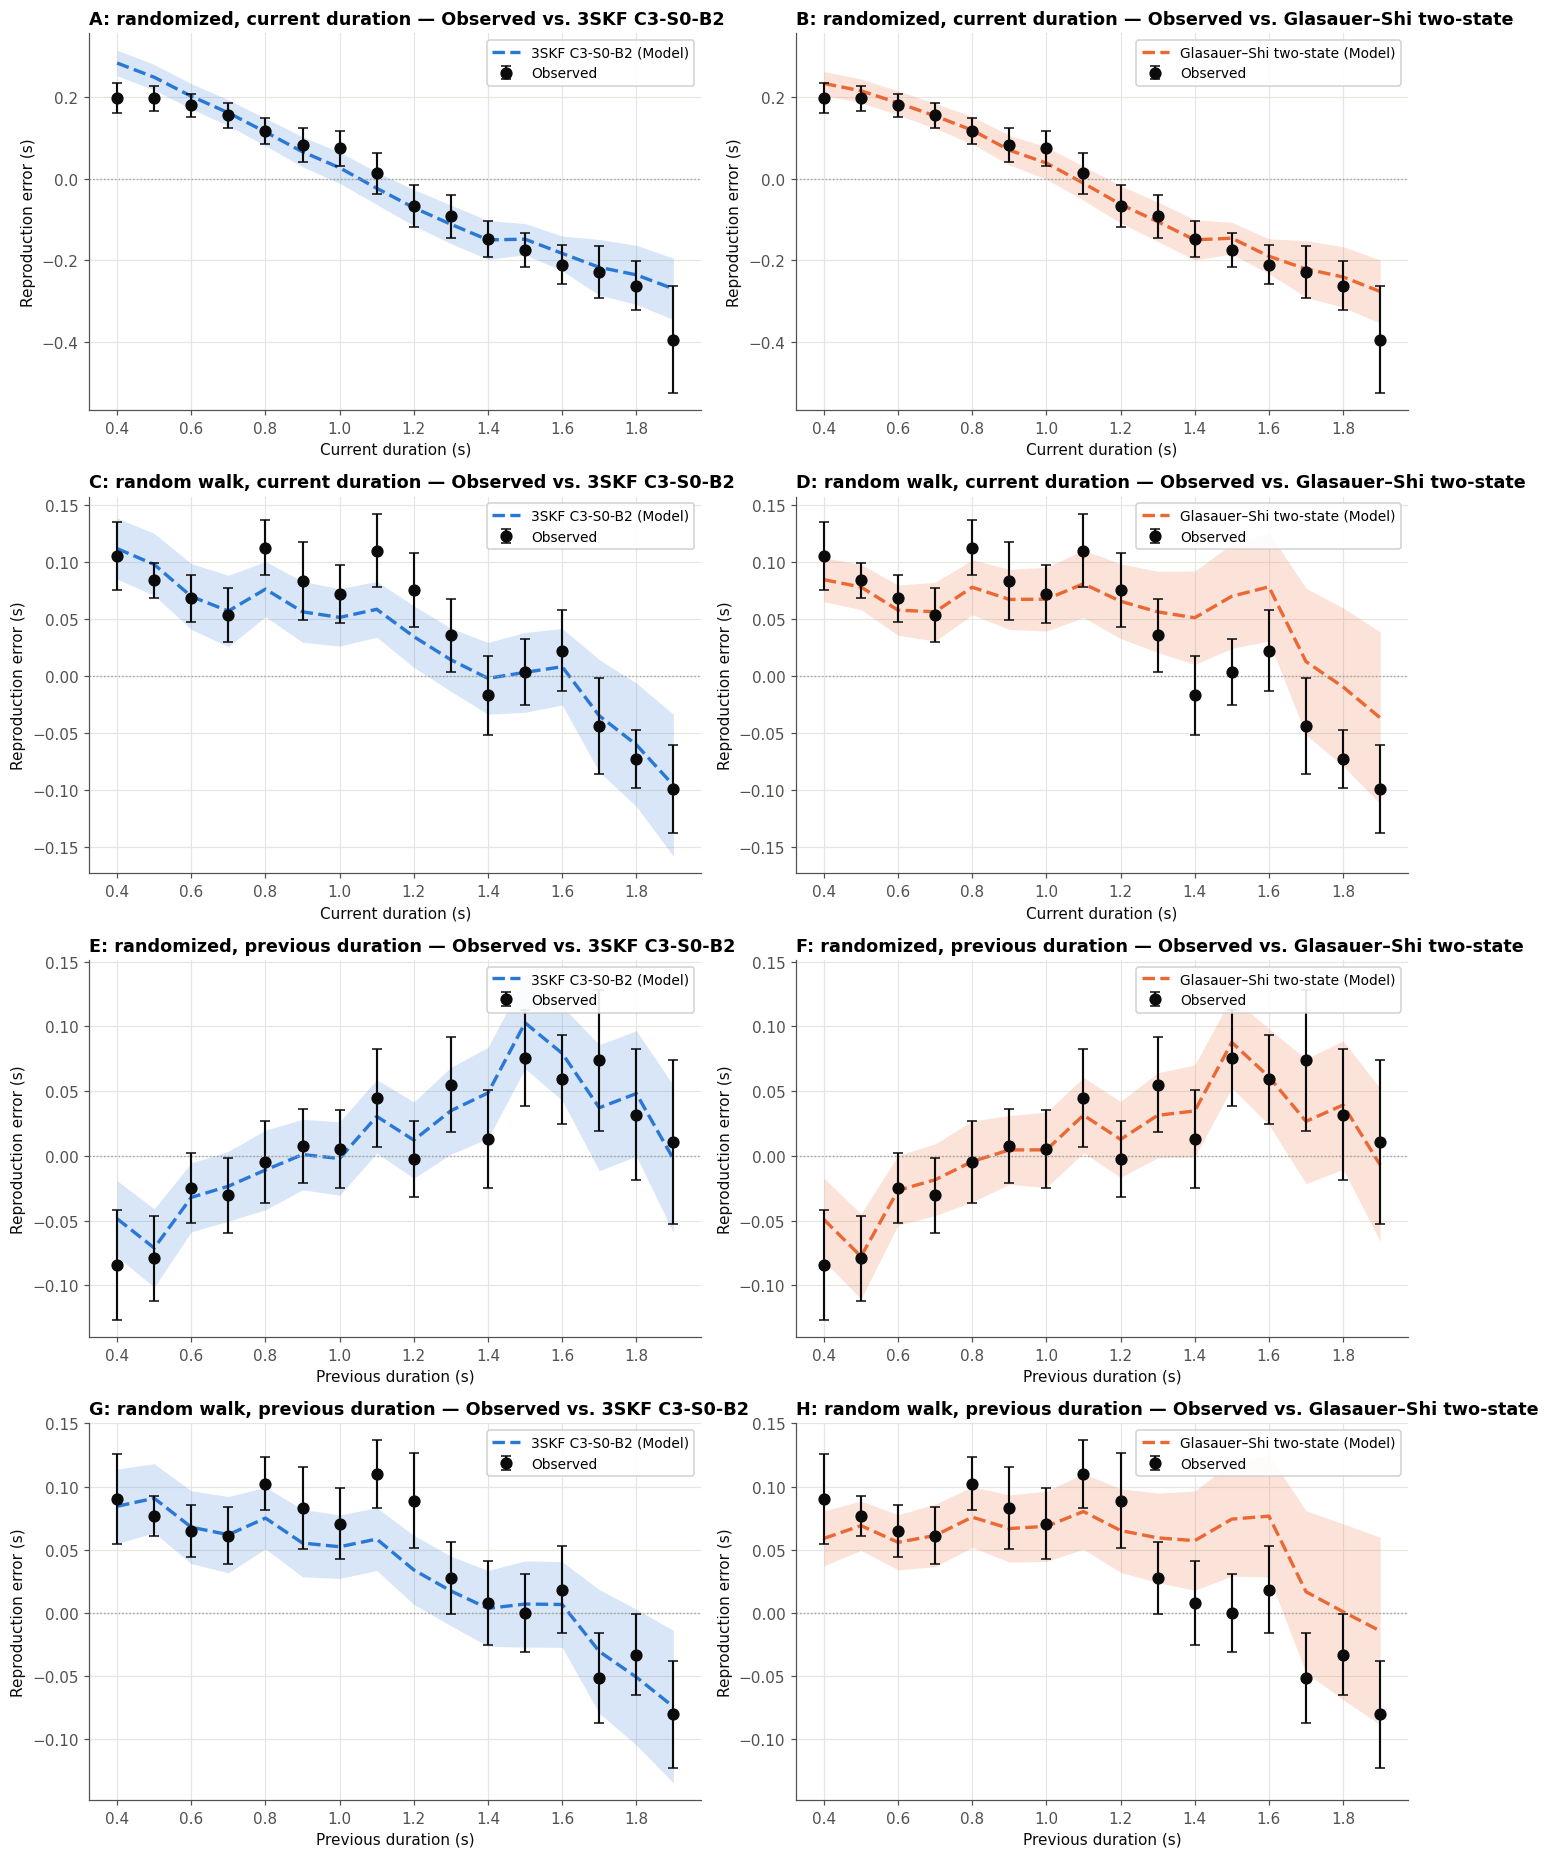

condition                                 random walk  randomized
model                  curve                                     
3SKF C3-S0-B2          current duration        0.8750      0.9380
                       lag-2 duration          0.6930      0.8540
                       previous duration       0.8230      0.8090
Glasauer–Shi two-state current duration        0.5920      0.9630
                       lag-2 duration          0.3640      0.7830
                       previous duration       0.4830      0.8390

In [4]:
curves = R.duration_curves(D)
R.plot_duration_curves(curves)
plt.show()
display(R.r_squared_table(curves))

For reference, the paper reports $R^2=(.964,.803,.834)$ for current, lag 1, and lag 2 in the randomized condition,
and $(.629,.544,.428)$ for the frozen-parameter random-walk prediction. The table above is recomputed from the
public CSV and the supplied model code; it reproduces the same pattern but is not silently replaced by the published
numbers where the numerical values differ.

### Lag 2 (supplementary)

Lag 2 is retained in the $R^2$ table because iterative models predict it, but it is not used to decide whether the
main CT/SD transfer worked. The primary comparison is current duration and lag 1.

## 4. Participant-level held-out comparison

Group-average $R^2$ is descriptive. The stronger test fits randomized trials only, freezes every parameter, and
scores each participant's random-walk responses. The LRZ run used 24 optimization starts plus a start at $\phi=0$,
for 3SKF and for its matched ablation without the bias state. It reports:

- trial-level RMSE of the predictive mean;
- mean log predictive density, which evaluates both location and uncertainty;
- absolute CT and SD prediction errors.

Differences are 3SKF minus the comparator. Negative values favor 3SKF for RMSE and absolute errors; positive
values favor it for log score. Confidence intervals bootstrap participants, and the $p$ value is an exact two-sided
participant-level sign-flip test ($2^{14}$ assignments).

In [5]:
comparison, means = R.transfer_tables()
display(comparison)
display(means)

preferred  \
comparator              metric                        
Glasauer–Shi two-state  trial-level RMSE      lower   
                        mean log score       higher   
                        absolute CT error     lower   
                        absolute SD error     lower   
3SKF B0 (no bias state) trial-level RMSE      lower   
                        mean log score       higher   
                        absolute CT error     lower   
                        absolute SD error     lower   

                                           3SKF C3-S0-B2 − comparator  \
comparator              metric                                          
Glasauer–Shi two-state  trial-level RMSE                      -0.0013   
                        mean log score                         0.0840   
                        absolute CT error                     -0.0271   
                        absolute SD error                     -0.0247   
3SKF B0 (no bias state) trial-level RMSE                       0.0013   
                        mean log score                         0.0722   
                        absolute CT error                      0.0099   
                        absolute SD error                      0.0099   

                                           95% CI low  95% CI high  exact p  \
comparator              metric                                                
Glasauer–Shi two-state  trial-level RMSE      -0.0089       0.0064   0.7502   
                        mean log score         0.0298       0.1483   0.0088   
                        absolute CT error     -0.0808       0.0274   0.3655   
                        absolute SD error     -0.0809       0.0317   0.4242   
3SKF B0 (no bias state) trial-level RMSE      -0.0007       0.0043   0.4963   
                        mean log score         0.0264       0.1265   0.0074   
                        absolute CT error     -0.0034       0.0312   0.4705   
                        absolute SD error     -0.0034       0.0313   0.4753   

                                           participants favoring 3SKF C3-S0-B2  
comparator              metric                                                  
Glasauer–Shi two-state  trial-level RMSE                                     9  
                        mean log score                                      11  
                        absolute CT error                                    9  
                        absolute SD error                                    8  
3SKF B0 (no bias state) trial-level RMSE                                     8  
                        mean log score                                      13  
                        absolute CT error                                    7  
                        absolute SD error                                    8

,trial-level RMSE,mean log score,absolute CT error,absolute SD error
model,,,,
3SKF B0 (no bias state),0.1913,0.2190,0.1083,0.1096
3SKF C3-S0-B2,0.1926,0.2912,0.1181,0.1195
Glasauer–Shi two-state,0.1939,0.2072,0.1453,0.1442


**Reading.**

* <span style="color:#b71c1c">**Against the paper two-state model.** 3SKF C3-S0-B2 has the better held-out log score: $+.084$,
  95% CI $[.030,.148]$, exact $p=.009$, 11 of 14 participants.</span> RMSE and the absolute CT and SD errors do not
  differ (CIs include 0, $p\ge.37$).
* <span style="color:#b71c1c">**Against the matched ablation without the bias state.** The bias state improves the log score by $.072$,
  95% CI $[.026,.127]$, $p=.007$, 13 of 14 participants.</span> The point-prediction metrics do not differ.
* The third state therefore helps the predictive response distribution, not the trial-wise mean.

### In-sample AIC on the randomized condition

Both models are fitted to the same randomized trials (the paper model is fitted only to this condition), and both
log-likelihoods are in seconds. The two-state model has $k=4$ ($v/r$, $q/r$, $\Delta x$, $\sigma$) with log encoding
and Gaussian noise; 3SKF C3-S0-B2 has $k=7$ with linear encoding. The models are not nested, so AIC is the comparison.

In [6]:
aic_means, aic_test = R.aic_comparison()
display(aic_means)
display(aic_test)

,mean AIC per participant
Glasauer–Shi two-state,-166.3663
3SKF B0 (no bias state),-164.5385
3SKF C3-S0-B2,-174.8056


,3SKF C3-S0-B2 − two-state (mean),participants favoring 3SKF C3-S0-B2,Wilcoxon p
0,-8.4393,8/14,0.1937


**Reading.**

* <span style="color:#b71c1c">**In-sample AIC slightly favors 3SKF C3-S0-B2 over the two-state model:** 8.4 units per
  participant on average. The advantage is not consistent: 8 of 14 participants, Wilcoxon $p=.19$.</span>
* 3SKF C3-S0-B2 beats its own ablation without the bias state by 10.3 units (10 of 14 participants).
* The models differ in more than the number of states: 3SKF here uses linear encoding, the two-state model log
  encoding. The decisive comparison is the held-out random-walk prediction above, not the in-sample fit.

## 5. Parameters and Kalman gains by sequence type

This design has no coherence manipulation, so the 3SKF fits contain no coherence term. To see how the fitted observer
differs between the two sequences, 3SKF (B2, one readout persistence $\phi$) was fitted separately to each sequence of
each participant: 5 starts plus a start at $\phi=0$, with every trial entered identically.

The figures follow the layout of the parameter figure of the intro-integration manuscript (Figure 6): one x axis, and
two bars per quantity, randomized and random walk. The bars are the mean over participants ± SEM.

* **Gains.** The gains are means over that sequence's trials at the fitted parameters.
* **Units.** $q_1$ and $q_2$ are in units of the measurement variance ($R=1$). The B2 response-bias drift is shown as
  $\sigma_b=\sqrt{q_3}$ in seconds, the quantity the likelihood uses.
* **Tests.** The table gives paired Wilcoxon signed-rank tests, randomized against random walk.

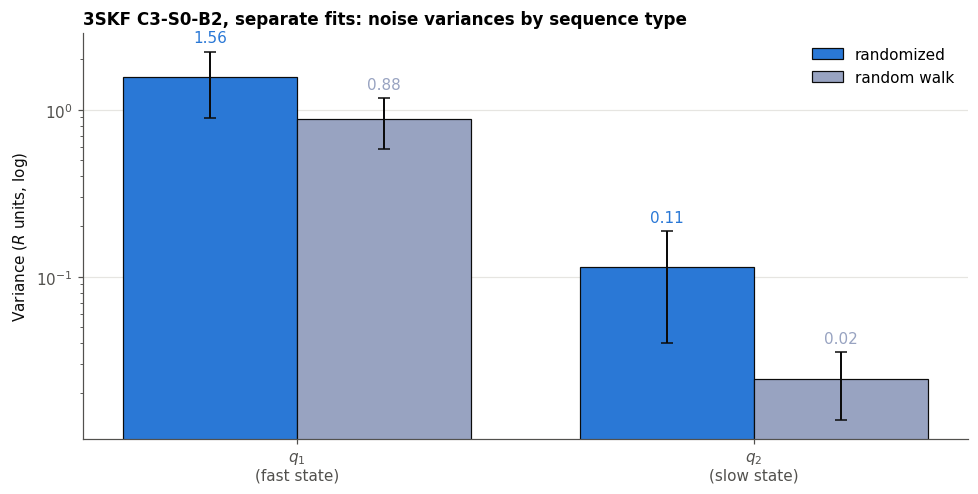

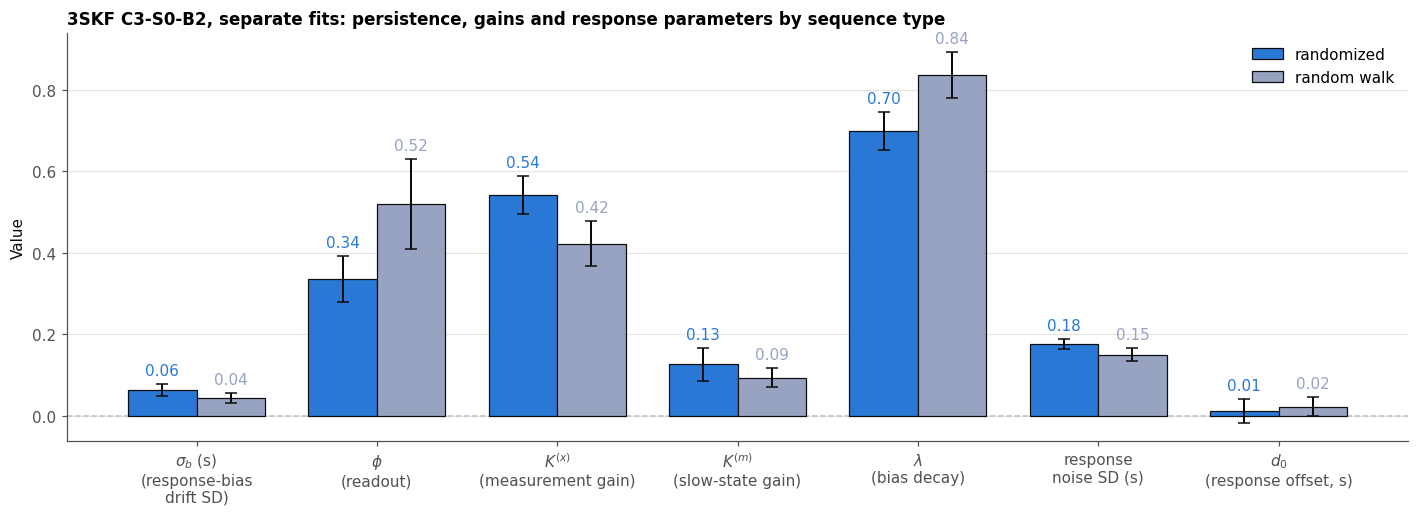

,randomized (median),random walk (median),randomized > random walk,Wilcoxon p
quantity,,,,
q1,0.8481,0.6663,8/14,0.3575
q2,0.0076,0.0037,8/14,0.3396
"σ_b (s), B2 bias drift SD",0.0466,0.0189,8/14,0.2166
λ,0.6299,0.9212,5/14,0.0906
φ,0.3696,0.5235,5/14,0.1726
K(x),0.5208,0.4541,8/14,0.0676
K(m),0.0783,0.0501,9/14,0.4263
response noise SD,0.1723,0.1244,11/14,0.0166
d0,0.0385,0.0255,8/14,0.8077


In [7]:
sequence_parameters = R.sequence_parameters(D)
R.plot_sequence_parameters(sequence_parameters)
plt.show()
display(R.sequence_tests(sequence_parameters))

**Reading.**

* <span style="color:#b71c1c">**Only the response noise differs reliably between the sequences.** It is smaller in
  random walk: median .124 against .172 s, 11 of 14 participants, $p=.017$.</span>
* The process noises $q_1$ and $q_2$, the response-bias drift $\sigma_b$ (median .047 against .019 s, $p=.22$) and
  the readout persistence $\phi$ do not differ (all $p>.17$).
* Two trends do not reach significance: a lower measurement gain in random walk ($K^{(x)}$ .45 against .52, $p=.068$)
  and a more persistent bias state ($\lambda$ .92 against .63, $p=.091$).
* This agrees with the transfer test: the change in CT and SD between the sequences needs no change in the observer.
  These separate fits are descriptive, with 6 starts each.

# What this notebook supports

1. **Partial-correlation check.** The randomized data reproduce the paper's check: mean
   $r(e_i,s_{i-1}\mid s_i)=.197$ and $r(e_i,s_i\mid s_{i-1})=-.603$ (both $p<.0001$).
2. <span style="color:#b71c1c">**CT and SD differ strongly between the sequences.** CT .455 against .096
   ($p<.001$, 14/14); SD .109 against $-.086$ ($p<.001$).</span>
3. **Paper two-state model.** It fits the randomized curves ($R^2=.963$ current, $.839$ lag 1). Frozen and applied to
   random walk, it predicts the curves less well ($R^2=.592$ and $.483$) and underestimates the random-walk CT and SD
   (CT .014 against .096, SD $-.006$ against $-.086$).
4. <span style="color:#b71c1c">**3SKF C3-S0-B2 (the Experiment 1 model, unchanged).** It fits the randomized curves ($R^2=.938$ and $.809$). Frozen, it
   predicts the random-walk curves ($R^2=.875$ and $.823$) and the random-walk CT and SD (.091 and $-.084$; paired
   tests against the data $p=.90$ and $.96$). The sequence effect on CT and SD therefore needs no parameter
   change.</span>
5. <span style="color:#b71c1c">**Held-out log score.** 3SKF C3-S0-B2 beats the paper model ($+.084$, $p=.009$) and the matched
   ablation without the bias state ($+.072$, $p=.007$, 13/14).</span> Point-prediction metrics (RMSE, absolute CT and SD errors) do
   not differ significantly.
6. **In-sample AIC (randomized).** 3SKF C3-S0-B2 is 8.4 units better than the two-state model on average, but only in 8 of 14
   participants ($p=.19$).
7. **Parameters by sequence type (separate fits).** Fitted separately to each sequence, only the response noise differs
   (smaller in random walk, $p=.017$). The process noises, $\phi$ and the gains do not differ significantly.
8. **What is not claimed.** No claim depends on a PPC threshold, simulated-cohort interval, static model or
   simple-iterative model.